Original Network Event Dataset:
   src_bytes  dst_bytes  count
0        100        200      5
1        120        210      6
2         90        180      4
3        110        220      5
4       5000         50    100
5       6000         40    120
6       7000         30    150
7       8000         20    180

K-Means Clustering Results:
   src_bytes  dst_bytes  count  cluster  category
0        100        200      5        0    Normal
1        120        210      6        0    Normal
2         90        180      4        0    Normal
3        110        220      5        0    Normal
4       5000         50    100        1  Abnormal
5       6000         40    120        1  Abnormal
6       7000         30    150        1  Abnormal
7       8000         20    180        1  Abnormal

Cluster Mapping:
Normal Cluster: 0
Abnormal Cluster: 1


C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


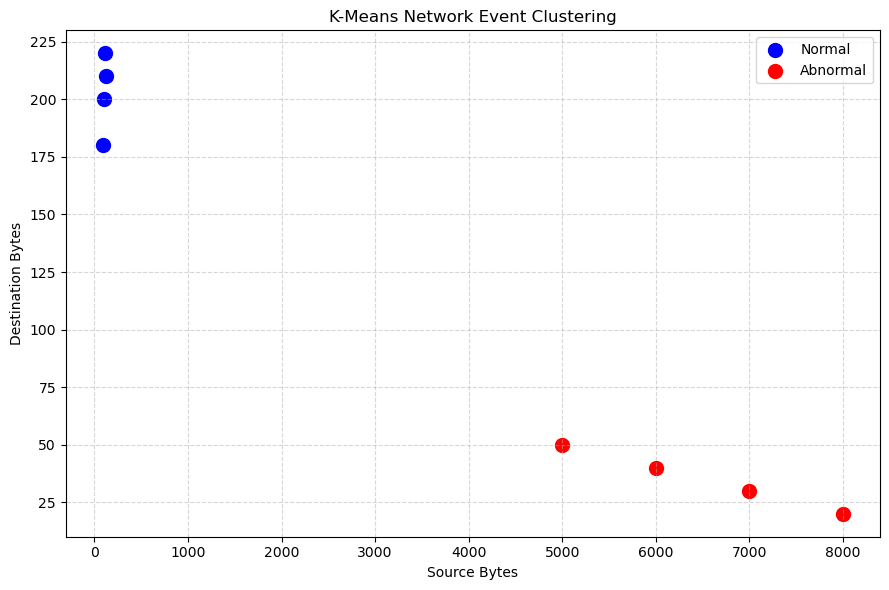

In [3]:
# K-Means Network Event Clustering
# Normal and Abnormal Network Event Detection

import os

# Fix Windows MKL warning
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# --------------------------------
# Step 1: Create Synthetic Dataset
# --------------------------------

data = {
    "src_bytes": [100, 120, 90, 110, 5000, 6000, 7000, 8000],
    "dst_bytes": [200, 210, 180, 220, 50, 40, 30, 20],
    "count": [5, 6, 4, 5, 100, 120, 150, 180]
}

df = pd.DataFrame(data)

print("Original Network Event Dataset:")
print(df)

# --------------------------------
# Step 2: Standardize Features
# --------------------------------

features = ["src_bytes", "dst_bytes", "count"]

scaler = StandardScaler()
X = scaler.fit_transform(df[features])

# --------------------------------
# Step 3: Apply K-Means Clustering
# --------------------------------

model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["cluster"] = model.fit_predict(X)

# --------------------------------
# Step 4: Map Clusters to Categories
# --------------------------------

cluster_means = df.groupby("cluster")["count"].mean()

normal_cluster = cluster_means.idxmin()
abnormal_cluster = cluster_means.idxmax()

df["category"] = df["cluster"].apply(
    lambda cluster: (
        "Normal"
        if cluster == normal_cluster
        else "Abnormal"
    )
)

# --------------------------------
# Step 5: Display Results
# --------------------------------

print("\nK-Means Clustering Results:")
print(df)

print("\nCluster Mapping:")
print("Normal Cluster:", normal_cluster)
print("Abnormal Cluster:", abnormal_cluster)

# --------------------------------
# Step 6: Visualize Results
# --------------------------------

plt.figure(figsize=(9, 6))

normal_data = df[df["category"] == "Normal"]
abnormal_data = df[df["category"] == "Abnormal"]

plt.scatter(
    normal_data["src_bytes"],
    normal_data["dst_bytes"],
    color="blue",
    label="Normal",
    s=100
)

plt.scatter(
    abnormal_data["src_bytes"],
    abnormal_data["dst_bytes"],
    color="red",
    label="Abnormal",
    s=100
)

plt.xlabel("Source Bytes")
plt.ylabel("Destination Bytes")
plt.title("K-Means Network Event Clustering")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()